In [ ]:
import pandas as pd

data_alexithymia_csv = pd.read_csv('data_alexithymia.csv', delimiter=';')
print(data_alexithymia_csv.head())


   ID Sex  Age  X.confused  X.right.words  X.sensations  X.describe  \
0   1   F   19           0              0             0           3   
1   2   M   19           3              3             0           3   
2   3   M   18           3              1             0           3   
3   4   M   18           2              0             0           4   
4   5   M   18           1              2             0           4   

   X.analyze.problems  X.upset  X.puzzled  ...  X.describe.more  X.going.on  \
0                   1        0          0  ...                0           0   
1                   4        2          1  ...                0           1   
2                   3        0          0  ...                0           0   
3                   4        0          2  ...                0           0   
4                   4        1          0  ...                2           0   

   X.why.angry  X.daily.activities  X.entertainment  X.reveal.feelings  \
0            0          

In [ ]:
print(data_alexithymia_csv.shape)



(122, 24)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
TA_20_cols = [col for col in data_alexithymia_csv.columns if col.startswith('X.')]
tas_data_20 = data_alexithymia_csv[TA_20_cols]



In [ ]:
print(data_alexithymia_csv.columns)


Index(['ID', 'Sex', 'Age', 'X.confused', 'X.right.words', 'X.sensations',
       'X.describe', 'X.analyze.problems', 'X.upset', 'X.puzzled',
       'X.let.happen', 'X.identify', 'X.essential', 'X.feel.about.people',
       'X.describe.more', 'X.going.on', 'X.why.angry', 'X.daily.activities',
       'X.entertainment', 'X.reveal.feelings', 'X.close', 'X.useful',
       'X.hidden.meanings', 'CESD'],
      dtype='object')


In [ ]:
standardize_scaler = StandardScaler()

if tas_data_20.empty:
    print("No TAS-20 columns found. Check your column name filter.")
else:
    tas_data_20_scaled = standardize_scaler.fit_transform(tas_data_20)
    print(tas_data_20_scaled)

[[-1.55051526 -1.40950457 -0.55993385 ...  1.04215963 -0.42949507
   0.77288774]
 [ 1.00573963  0.9461058  -0.55993385 ... -0.76129391  0.48977509
  -0.20932376]
 [ 1.00573963 -0.62430111 -0.55993385 ...  0.14043286 -0.42949507
  -1.19153526]
 ...
 [-1.55051526  0.16090235 -0.55993385 ...  1.04215963 -0.42949507
   0.77288774]
 [-1.55051526 -0.62430111 -0.55993385 ...  0.14043286 -1.34876524
   0.77288774]
 [-0.6984303  -0.62430111 -0.55993385 ...  0.14043286 -0.42949507
   0.77288774]]


In [ ]:
run_pca = PCA()
run_pca.fit(tas_data_20_scaled)

attribute_variance = run_pca.explained_variance_ratio_
print(f"Explained Variance Ratio per attribute/component: {attribute_variance}")

Explained Variance Ratio per attribute/component: [0.23633569 0.1277815  0.07956262 0.07264861 0.05927742 0.05410012
 0.04542591 0.04335007 0.03817455 0.03467543 0.03385417 0.02644855
 0.02467155 0.02375451 0.02245289 0.02123107 0.01852421 0.01556533
 0.01203223 0.01013357]


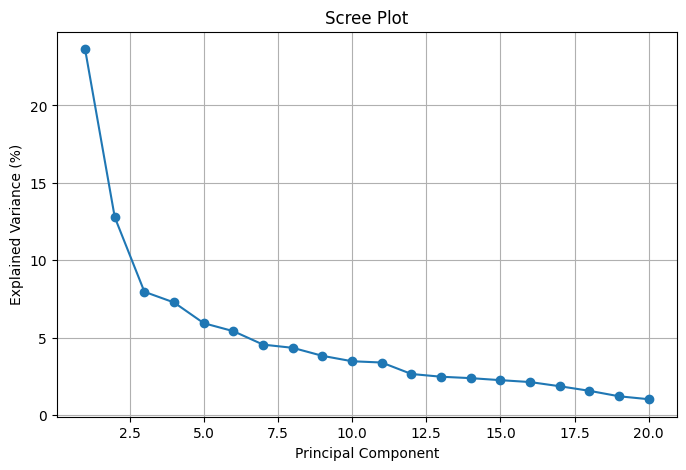

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), attribute_variance * 100, marker='o', linestyle='-')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.grid(True)
plt.show()

In [ ]:
!pip install factor_analyzer


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42657 sha256=f8c24c5641b3f344393155c3b6263b824e1666560462bacbac497c59531ce920
  Stored in directory: /root/.cache/pip/wheels/fa/f7/53/a55a8a56668a6fe0199e0e02b6e0ae3007ec35cdf6e4c25df7
Successfully built factor_analyzer


In [ ]:
from factor_analyzer.rotator import Rotator
from sklearn.decomposition import PCA

rotator = Rotator(method='varimax')
rotated_components = rotator.fit_transform(run_pca.components_.T)
rotated_df = pd.DataFrame(rotated_components, index=TA_20_cols)
print(rotated_df)


                               0             1             2             3   \
X.confused           4.565824e-09 -8.427632e-09 -4.782854e-08  3.427850e-09   
X.right.words        1.000000e+00 -1.121586e-09 -1.249088e-08 -3.221997e-10   
X.sensations        -2.512789e-09  2.089612e-10 -6.868515e-09  8.518364e-11   
X.describe          -6.099412e-07 -5.561775e-10  3.406958e-09 -1.828117e-10   
X.analyze.problems  -5.433515e-12 -3.666109e-08 -8.381428e-09 -1.366552e-09   
X.upset             -1.274442e-09 -2.685565e-09 -6.622347e-09 -9.069521e-10   
X.puzzled           -4.270038e-09  4.291252e-08 -2.620288e-08  4.086931e-09   
X.let.happen        -6.407930e-10  8.623139e-11  9.123882e-09 -8.198749e-09   
X.identify           3.940349e-09  5.002262e-09 -1.907491e-09  2.598728e-09   
X.essential          1.959920e-09 -1.303828e-09 -2.759618e-09  1.389576e-09   
X.feel.about.people  9.241509e-09  4.823782e-07 -1.246094e-07 -4.052675e-10   
X.describe.more      4.483858e-10  6.687041e-10 -1.7

In [23]:
pca_scores = run_pca.transform(tas_data_20_scaled)


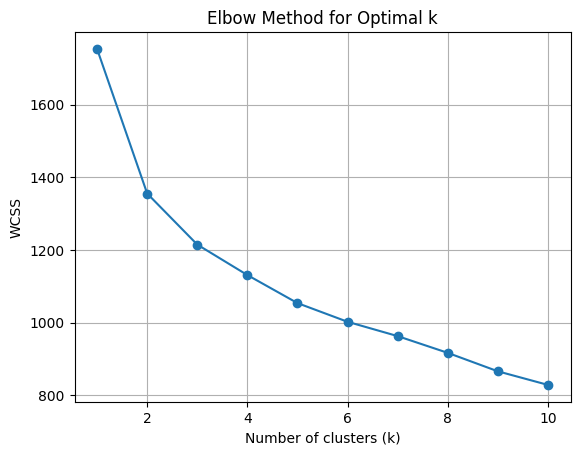

In [25]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=0)
    kmeans.fit(pca_scores[:, :8])
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()